# Uncertainty Estimation Practical — Part II
This notebook is self-contained and uses the same spiral data construction as Part I. Complete the three marked implementation tasks, then answer the discussion questions.

**Running in Google Colab.** Open the `.ipynb` using **File > Upload notebook**, connect to a Python runtime, and run cells in order. A CPU runtime is sufficient for the core exercises. Use the runtime's existing `jax`, `numpy`, and `matplotlib`; no toy-data download is needed. If an import reports a missing package, run `%pip install jax numpy matplotlib` in a setup cell before the imports, then restart the runtime. For local Jupyter, follow `README.md`. After changing a training setting, restart the runtime/kernel and run all cells again: JAX-compiled functions may otherwise retain previously captured optimizer settings. Training settings remain at the start of each training cell.

**Note.** for this year an LLM has been used to polish this course exercise. Please report to the teachers if you encounter an issue with the notebook.


## Training Independent Subnetworks for Robust Prediction — Havasi et al. (2021)

### Motivation
A [deep ensemble](https://arxiv.org/abs/1612.01474) trains and stores several networks. This can increase training cost, inference computation, and memory use. Distillation can reduce deployment cost after training an ensemble. Weight-sharing methods instead aim to obtain multiple predictions within a more compact model.

Here we study [multi-input multi-output (MIMO) networks](https://arxiv.org/abs/2010.06610). A shared hidden network receives $M$ input slots and produces $M$ output heads. The first and final layers grow with $M$, while hidden-layer widths remain unchanged. Thus this is a computational trade-off, not literally a zero-cost ensemble; do not assume that its heads are statistically independent simply because they are called subnetworks.

### Original paper's abstract (2021)
The following reports the paper's results, not a guarantee for this toy network.

"
Recent approaches to efficiently ensemble neural networks have shown that strong robustness and uncertainty performance can be achieved with a negligible gain in parameters over the original network. However, these methods still require multiple forward passes for prediction, leading to a significant computational cost. In this work, we show a surprising result: the benefits of using multiple predictions can be achieved `for free' under a single model's forward pass. In particular, we show that, using a multi-input multi-output (MIMO) configuration, one can utilize a single model's capacity to train multiple subnetworks that independently learn the task at hand. By ensembling the predictions made by the subnetworks, we improve model robustness without increasing compute. We observe a significant improvement in negative log-likelihood, accuracy, and calibration error on CIFAR10, CIFAR100, ImageNet, and their out-of-distribution variants compared to previous methods.
"

### Method
The shape flow below replaces the externally hosted illustration so that the instructions remain available offline:

```text
Training tuple:  (x_1, ..., x_M), generally different examples
Flatten inputs:  M × D → shared hidden layers → M × K logits
Targets:         (y_1, ..., y_M), aligned with their input slots

Inference tuple: (x, ..., x), the SAME example in every slot
Prediction:      average the M heads' class probabilities
```

For training, independently permute the batch for each head, using a different PRNG subkey. Apply each head's permutation to **both inputs and targets**. Reusing one common permutation would make every head see the same example in each tuple and would not implement this construction.

At evaluation, repeat each input across all slots. Do not shuffle the input, and do not average logits. Note that training uses mixed tuples whereas evaluation uses repeated inputs; this is a deliberate feature of the basic MIMO method studied here.

### Implementation tasks
1. **Architecture:** expand the input and output layer sizes to $MD$ and $MK$, keeping hidden widths at 150.
2. **Training loss:** construct the independently shuffled inputs/targets and average categorical cross-entropy over the $MN$ head-example pairs. Sum over classes. Add the same $\lambda\|\theta\|_2$ penalty as in Part I, **once**, after averaging the NLL. This explicit normalization fixes the meaning of `wd`; summing instead of averaging over heads would change the relative strength of the penalty.
3. **Evaluation:** duplicate inputs to shape $(M,N,D)$, evaluate the network, and return the mean and individual head probabilities.

## Classification on [toy dataset] using MIMO :
[toy dataset]: https://cs231n.github.io/neural-networks-case-study/

In [14]:
# Start in a fresh runtime; no %reset magic is needed.
# Colab: use the existing JAX, NumPy, and Matplotlib.
# Only if an import reports a missing package, install it before importing:
# %pip install jax numpy matplotlib
# Then restart the runtime. For local Jupyter setup, see README.md.

In [15]:
import jax
import jax.numpy as jnp
from jax import grad, jit, vmap, random
from jax.scipy.special import logsumexp
from jax.example_libraries import optimizers
from jax import config
from functools import partial
import matplotlib.pyplot as plt
import numpy as np
import time

# For debugging, set True before running the notebook from a fresh kernel.
# jax_debug_nans can also help locate non-finite computations.
config.update("jax_disable_jit", False)
print("JAX:", jax.__version__, "| Devices:", jax.devices())

JAX: 0.7.2 | Devices: [CpuDevice(id=0)]


In [16]:
def one_hot(x, k, dtype=jnp.float32):
    """One-hot encode integer class labels."""
    return jnp.asarray(x[:, None] == jnp.arange(k), dtype)

def generate_datasets(N, K, noise, seed=0):
    """N points per class in a two-dimensional spiral; local, reproducible RNG."""
    rng = np.random.RandomState(seed)
    X = np.zeros((N * K, 2), dtype=np.float32)
    y = np.zeros(N * K, dtype=np.int32)
    for j in range(K):
        ix = slice(N * j, N * (j + 1))
        r = np.linspace(0.0, 1.0, N)
        t = np.linspace(j * 8, (j + 1) * 8, N) + rng.randn(N) * noise * (r + 1.0)
        X[ix] = np.c_[r * np.sin(t), r * np.cos(t)]
        y[ix] = j
    X, y = jnp.asarray(X), jnp.asarray(y)
    return X, y, one_hot(y, K)

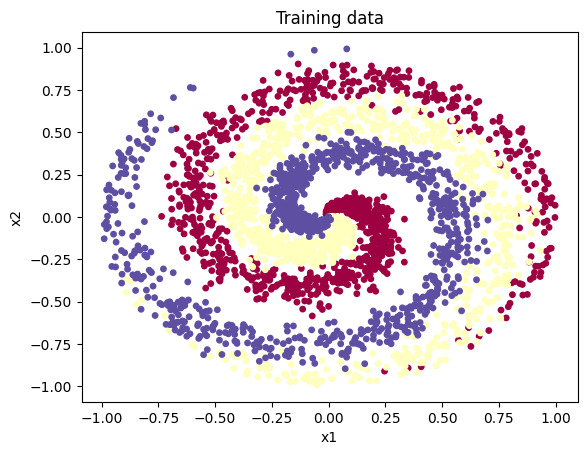

Training: (3000, 2) (3000,) | Held-out: (3000, 2) (3000,)


In [17]:
N = 1000  # points per class
D = 2
K = 3
X, y, y_onehot = generate_datasets(N, K, noise=0.3, seed=0)
# Independent noise realization on the same radial grid; never used for training.
X_test, y_test, y_test_onehot = generate_datasets(N, K, noise=0.3, seed=1)
plt.figure()
plt.scatter(X[:, 0], X[:, 1], c=y, s=15, cmap=plt.cm.Spectral)
plt.title("Training data")
plt.xlabel("x1")
plt.ylabel("x2")
plt.show()
print("Training:", X.shape, y.shape, "| Held-out:", X_test.shape, y_test.shape)

In [18]:
# A helper function to randomly initialize weights and biases
# for a dense neural network layer
def random_layer_params(m, n, key, scale=1e-1):
    w_key, b_key = random.split(key)
    return scale * random.normal(w_key, (n, m)), scale * random.normal(b_key, (n,))

# Initialize all layers for a fully-connected neural network with sizes "sizes"
def init_network_params(sizes, key):
    keys = random.split(key, len(sizes))
    return [random_layer_params(m, n, k) for m, n, k in zip(sizes[:-1], sizes[1:], keys)]

def predict_MIMO(params, input):
    """
    The input is of shape (#nets, #examples, #input_dims)=(M,N,D).
    while the two outputs are of shape (#nets, #examples, #classes)=(M,N,K).
    """
    def _predict(params, input):
        M,D = input.shape
        input = input.reshape(M*D)
        activations = input
        for w, b in params[:-1]:
            outputs = jnp.dot(w, activations) + b
            activations = jax.nn.relu(outputs)

        final_w, final_b = params[-1]
        logits = jnp.dot(final_w, activations) + final_b
        logits = logits.reshape(M,-1)
        probs = jax.nn.softmax(logits, axis=1)
        return logits, probs

    logits, probs = vmap(_predict, in_axes=(None, 1))(params, input)
    logits, probs = jnp.transpose(logits, [1, 0, 2]), jnp.transpose(probs, [1, 0, 2])

    return logits, probs

@partial(jit, static_argnums=2)
def evalMIMO(params, inputs, M):
    """Repeat inputs (N,D) across slots to form (M,N,D), then predict.

    Return mean probabilities (N,K) and all head probabilities (M,N,K).
    Average probabilities over axis 0, not logits and not the class axis.
    """
    repeated_inputs = jnp.broadcast_to(inputs, (M,) + inputs.shape)
    _, probabilities = predict_MIMO(params, repeated_inputs)
    return jnp.mean(probabilities, axis=0), probabilities

def batched_logsumexp(logits):
    """Logits (M,N,K) -> normalization constants (M,N)."""
    return logsumexp(logits, axis=-1)

def lossMIMO(params, inputs, targets, M, wd, seed):
    """Independently shuffle each head's inputs AND corresponding targets.

    inputs (N,D), one-hot targets (N,K). Split the PRNG key into M subkeys;
    create one permutation per head and use it for both arrays. The batched
    shapes become (M,N,D) and (M,N,K). Sum CE over K, average over M and N,
    and add wd * optimizers.l2_norm(params) once. Return one scalar.
    """
    keys = random.split(seed, M)
    permutations = vmap(lambda key: random.permutation(key, inputs.shape[0]))(keys)
    shuffled_inputs = inputs[permutations]
    shuffled_targets = targets[permutations]
    logits, _ = predict_MIMO(params, shuffled_inputs)
    log_probs = jax.nn.log_softmax(logits, axis=-1)
    nll = -jnp.mean(jnp.sum(shuffled_targets * log_probs, axis=-1))
    return nll + wd * optimizers.l2_norm(params)

@partial(jit, static_argnames=("M", "opt_update", "get_params"))
def update_mimo(step, params, x, y, opt_state, M, wd, seed, opt_update, get_params):
    grads = grad(lossMIMO)(params, x, y, M, wd, seed)
    opt_state = opt_update(step, grads, opt_state)
    return get_params(opt_state), opt_state

@partial(jit, static_argnums=2)
def mimo_log_probabilities(params, inputs, M):
    """Stable log of the averaged head probabilities, for NLL reporting only."""
    repeated = jnp.broadcast_to(inputs, (M,) + inputs.shape)
    logits, _ = predict_MIMO(params, repeated)
    return logsumexp(jax.nn.log_softmax(logits, axis=-1), axis=0) - jnp.log(M)

def logging(params_mimo, X, y, M, log_acc_train, log_nll_train):
    # Exercise evalMIMO in evaluation, but compute NLL stably from logits.
    mean, _ = evalMIMO(params_mimo, X, M)
    log_probs = mimo_log_probabilities(params_mimo, X, M)
    log_acc_train.append(float(jnp.mean(jnp.argmax(mean, axis=-1) == y)))
    log_nll_train.append(float(-jnp.mean(log_probs[jnp.arange(len(y)), y])))

In [19]:
# MIMO settings. Retrain from scratch whenever M changes.
M = 4
num_epochs = 2000
step_size = 0.1
wd = 1e-3  # coefficient of the same L2-NORM penalty as Part I

assert M >= 1 and num_epochs >= 1
# Expand the first and last layers for M input/output slots.
layer_sizes = [D * M, 150, 150, K * M]
assert layer_sizes[0] == D * M and layer_sizes[-1] == K * M

log_acc, log_nll = [], []
opt_init, opt_update, get_params = optimizers.adam(step_size)
params_mimo = init_network_params(layer_sizes, random.PRNGKey(0))
opt_state = opt_init(params_mimo)
key = random.PRNGKey(1)  # stream for training tuples, separate from initialization
start_time = time.perf_counter()
for epoch in range(num_epochs):
    key, seed = random.split(key)
    params_mimo, opt_state = update_mimo(
        epoch, params_mimo, X, y_onehot, opt_state, M, wd, seed, opt_update, get_params)
    logging(params_mimo, X, y, M, log_acc, log_nll)
    if epoch == 0 or (epoch + 1) % 200 == 0 or epoch + 1 == num_epochs:
        print(f"Epoch {epoch+1}: train accuracy {log_acc[-1]:.4f}; train NLL {log_nll[-1]:.4f}")
assert np.isfinite(log_nll).all(), "Non-finite MIMO NLL."
mimo_seconds = time.perf_counter() - start_time
heldout_acc, heldout_nll = [], []
logging(params_mimo, X_test, y_test, M, heldout_acc, heldout_nll)
print(f"Held-out accuracy {heldout_acc[-1]:.4f}; held-out NLL {heldout_nll[-1]:.4f}")
print(f"Training time: {mimo_seconds:.2f} s; parameters: {sum(p.size for p in jax.tree_util.tree_leaves(params_mimo)):,}")

Epoch 1: train accuracy 0.3333; train NLL 2.1503
Epoch 200: train accuracy 0.9050; train NLL 0.3007
Epoch 400: train accuracy 0.9280; train NLL 0.2035
Epoch 600: train accuracy 0.9393; train NLL 0.1832
Epoch 800: train accuracy 0.9457; train NLL 0.1669
Epoch 1000: train accuracy 0.9463; train NLL 0.1583
Epoch 1200: train accuracy 0.9423; train NLL 0.1589
Epoch 1400: train accuracy 0.9473; train NLL 0.1449
Epoch 1600: train accuracy 0.9390; train NLL 0.1826
Epoch 1800: train accuracy 0.9440; train NLL 0.1525
Epoch 2000: train accuracy 0.9493; train NLL 0.1508
Held-out accuracy 0.9367; held-out NLL 0.1854
Training time: 40.96 s; parameters: 25,812


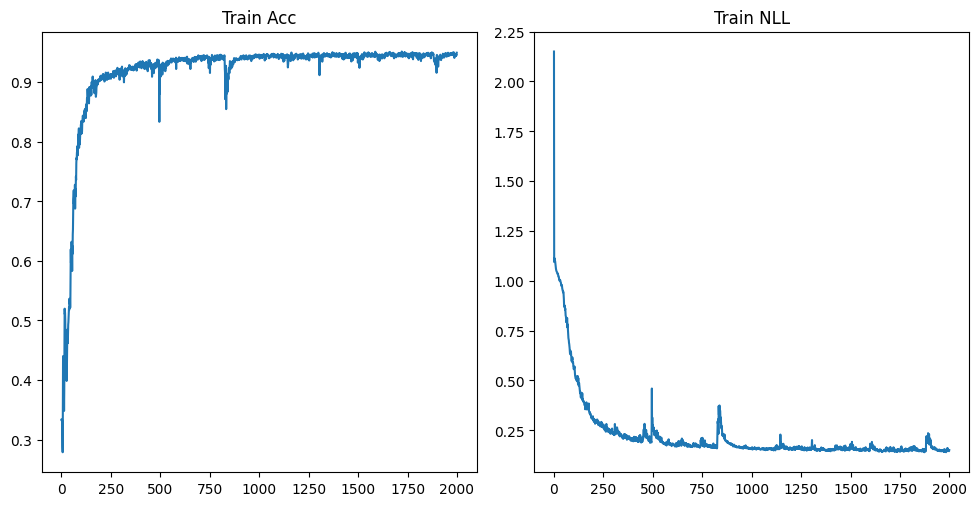

In [20]:
fig, axes = plt.subplots(1,2, figsize=(10,5))
fig.tight_layout()
axes[0].plot(log_acc)
axes[1].plot(log_nll)
axes[0].title.set_text('Train Acc')
axes[1].title.set_text('Train NLL')

In [21]:
def entropy(preds):
    """Categorical entropy in nats along the final axis; exactly 0*log(0)=0."""
    preds = np.asarray(preds, dtype=np.float64)
    safe = np.where(preds > 0, preds, 1.0)
    return -np.sum(preds * np.log(safe), axis=-1)

def js_terms(distributions):
    """Input (M, N, K); return total and average member entropy, each (N,)."""
    distributions = np.asarray(distributions)
    return entropy(distributions.mean(axis=0)), entropy(distributions).mean(axis=0)

def visualize_predictions(X, y, params_list, min=-2.0, max=2.0, res=200, num_nets=1):
    xs = np.linspace(min, max, res)
    ys = np.linspace(min, max, res)
    xy = np.asarray([(_x, _y) for _x in xs for _y in ys], dtype=np.float32)
    predictions_ensemble, probabilities = evalMIMO(params_list, xy, num_nets)
    predictions = np.asarray(probabilities)
    total, data_uncertainty = js_terms(predictions)
    knowledge = np.maximum(total - data_uncertainty, 0.0)  # roundoff only
    K_plot = predictions.shape[-1]
    levels = np.linspace(0, np.log(K_plot), 51)
    shape = (len(xs), len(ys))
    labels = np.argmax(predictions_ensemble, axis=-1).reshape(shape).T
    fig, axes = plt.subplots(2, 2, figsize=(10, 9), constrained_layout=True)
    axes = axes.flatten()
    class_norm = plt.matplotlib.colors.BoundaryNorm(np.arange(K_plot + 1) - 0.5, plt.cm.Spectral.N)
    axes[0].scatter(X[:, 0], X[:, 1], c=y, s=10, cmap=plt.cm.Spectral, norm=class_norm)
    axes[1].contourf(xs, ys, labels, levels=np.arange(K_plot + 1) - 0.5, cmap=plt.cm.Spectral, norm=class_norm)
    for ax, values, title in [(axes[2], data_uncertainty, "Average member entropy (data proxy)"),
                              (axes[3], knowledge, "Member disagreement (knowledge proxy)")]:
        contour = ax.contourf(xs, ys, values.reshape(shape).T, levels=levels, cmap="magma")
        fig.colorbar(contour, ax=ax, label="nats")
        ax.set_title(title)
    axes[0].set_title("Training data")
    axes[1].set_title("Ensemble predicted class")
    for ax in axes:
        ax.set(xlim=(min, max), ylim=(min, max), xlabel="x1", ylabel="x2", aspect="equal")
    plt.show()
    fig, ax = plt.subplots(figsize=(5, 4), constrained_layout=True)
    contour = ax.contourf(xs, ys, total.reshape(shape).T, levels=levels, cmap="magma")
    fig.colorbar(contour, ax=ax, label="nats")
    ax.set(title="Total predictive entropy", xlabel="x1", ylabel="x2", aspect="equal")
    plt.show()

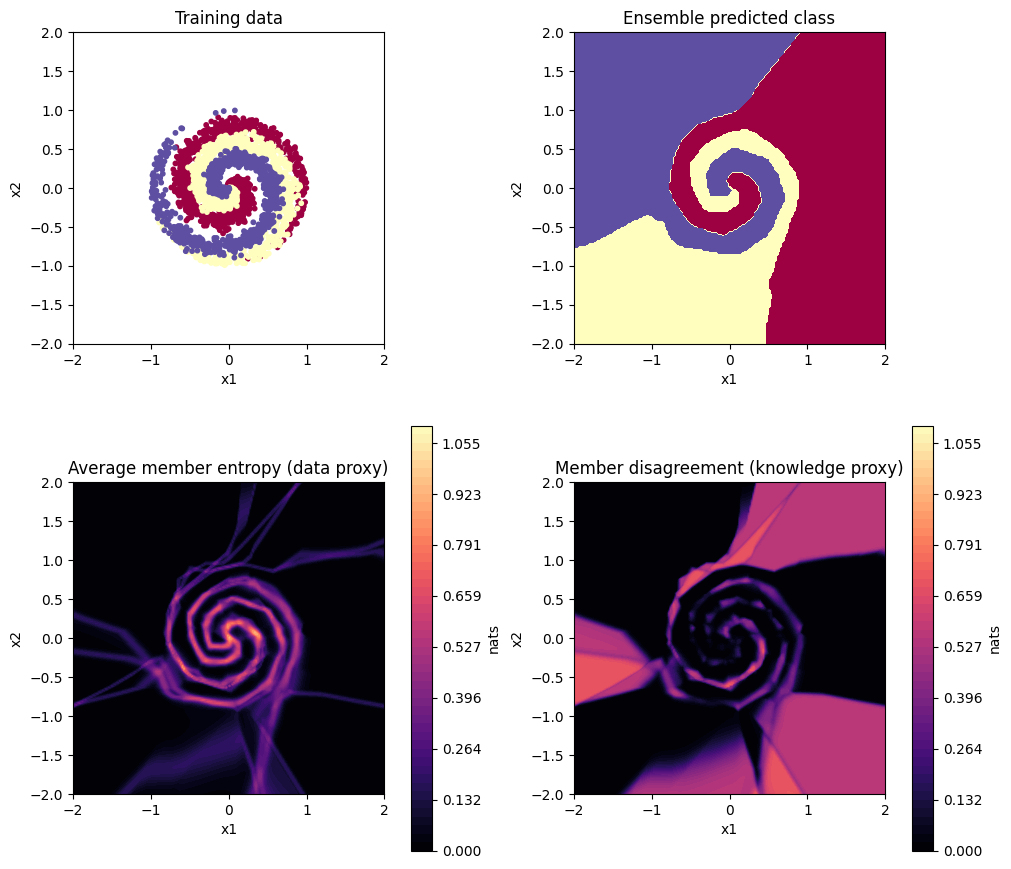

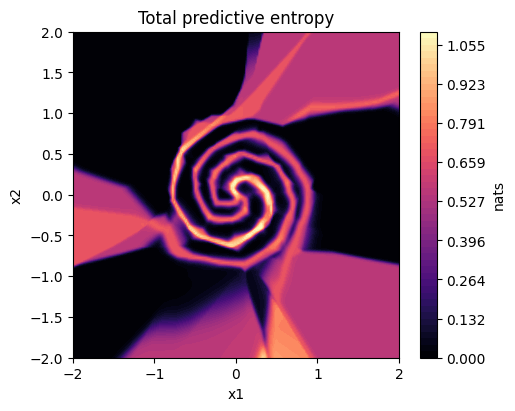

In [22]:
visualize_predictions(X, y, params_mimo, num_nets=M)

### Discussion — MIMO
1. Compare the predictions and uncertainty maps with Part I. Describe observed similarities and differences; neither agreement nor a particular uncertainty pattern is guaranteed.
2. Retrain with $M=1$ and $M=4$, and at least one larger value such as $M=8$, keeping the hidden widths fixed. Compare held-out accuracy/NLL, total entropy and disagreement. How might increasing the number of heads affect the capacity available per prediction? There need not be a monotonic increase in diversity or improvement in calibration.
3. Compare parameter counts and record the update budgets when comparing with deep ensembles. The supplied defaults use 300 updates per independent network in Part I and 2,000 updates of the shared MIMO model here; this is a qualitative demonstration, **not a matched-compute benchmark**. For a controlled timing comparison, also match a clearly stated budget and account for JAX compilation and synchronization.
4. Report your own approximate completion time.

The maps use nats and a common $[0,\log K]$ scale. Average member entropy and disagreement are model-based proxies, not independently verified measurements of irreducible noise or complete epistemic uncertainty. All spiral examples lie in the unit disk; low entropy elsewhere is unjustified confidence unless additional assumptions about the labels are supplied.

## Image classification
`classification_mnist_pytorch.py` is a **JAX** classifier that uses PyTorch/torchvision only for data loading (the historical filename is retained). Adapt it to either deep ensembles or MIMO. For deep ensembles, initialize and train separate parameter sets and average their class probabilities. For MIMO, use the input/target pairing and repeated-input inference from this notebook.

Install the optional dependencies and follow the command in `README.md`. MNIST requires a download on its first use. Compare a single model with your ensemble using test accuracy and test NLL; do not use the test set for tuning. Any bonus credit is subject to the course's grading policy.

## Completed head-count comparison
Retrain from scratch with 1, 4 and 8 heads, retaining 150-unit hidden layers and 2,000 updates. The default four-head fit is reused. All models use the same initialization seed and training-key stream. Parameter shapes differ, so their actual initial weights are not identical.

Finished MIMO: 1 heads; held-out accuracy 0.9473333358764648 NLL 0.1854575127363205


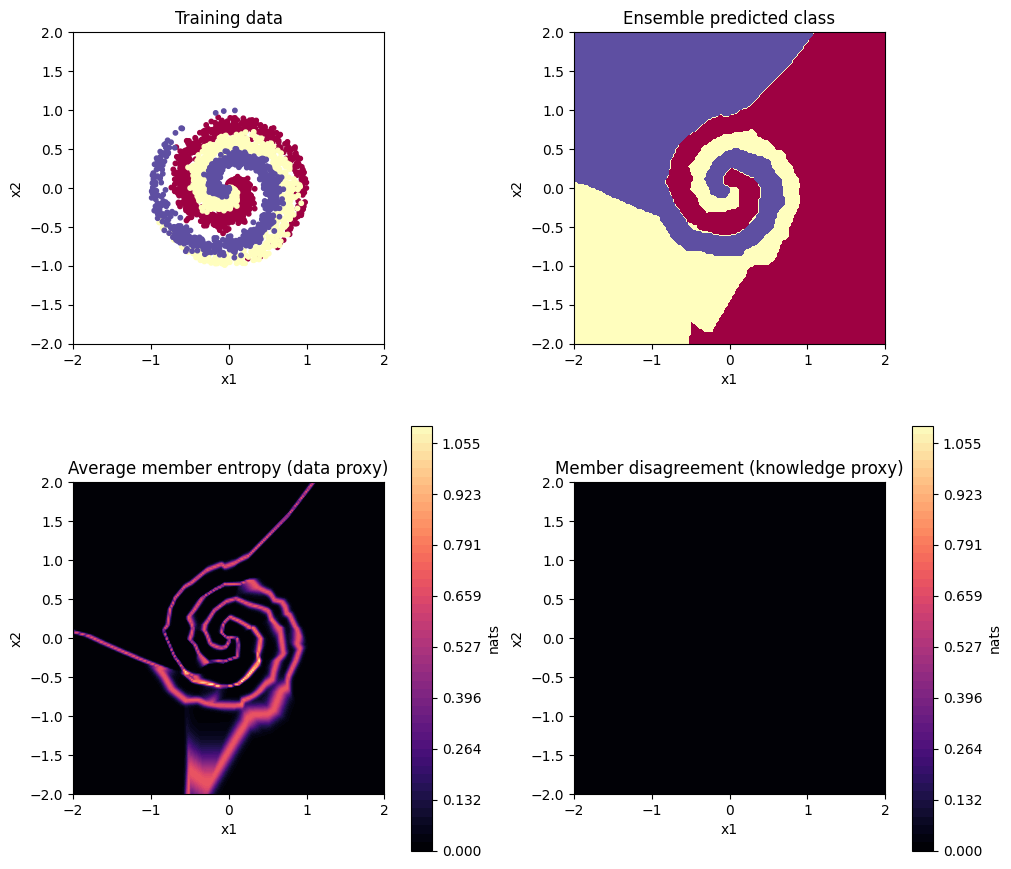

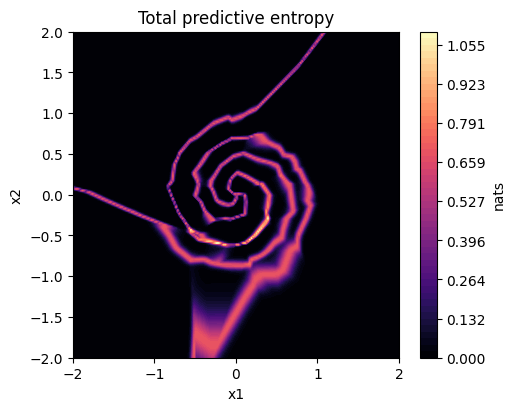

Finished MIMO: 4 heads; held-out accuracy 0.9366666674613953 NLL 0.185370072722435
Finished MIMO: 8 heads; held-out accuracy 0.9073333144187927 NLL 0.5293955206871033


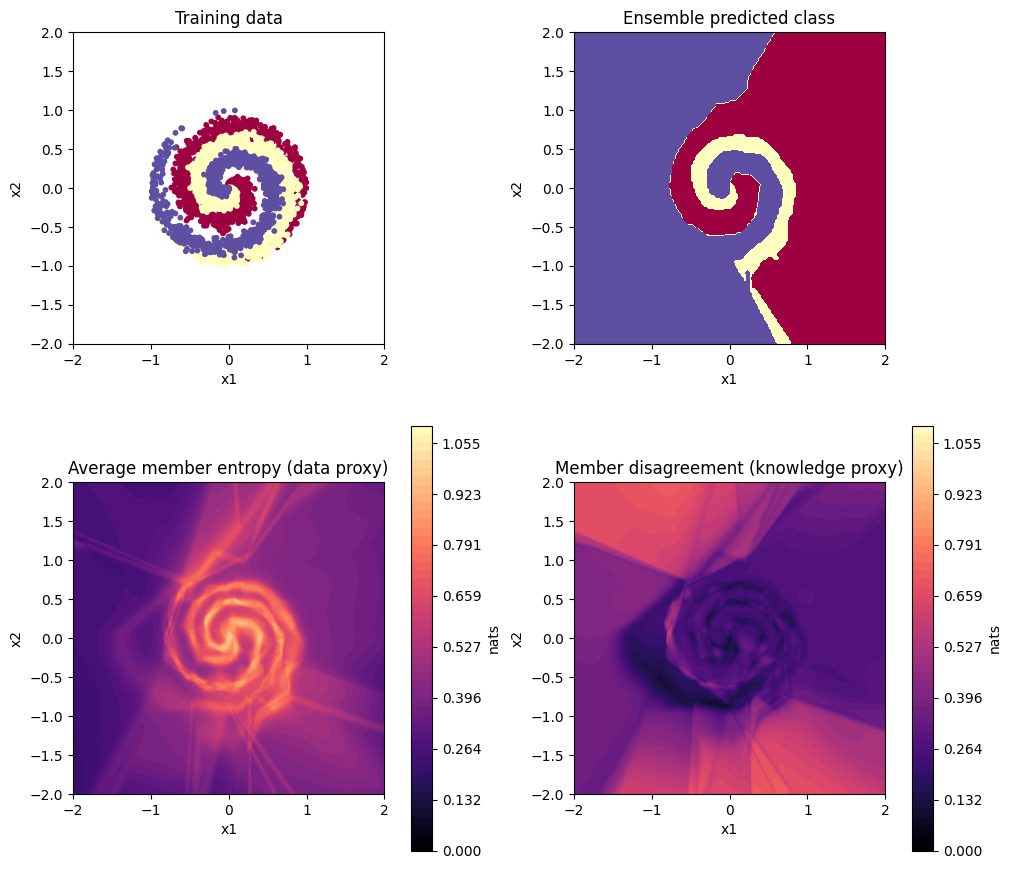

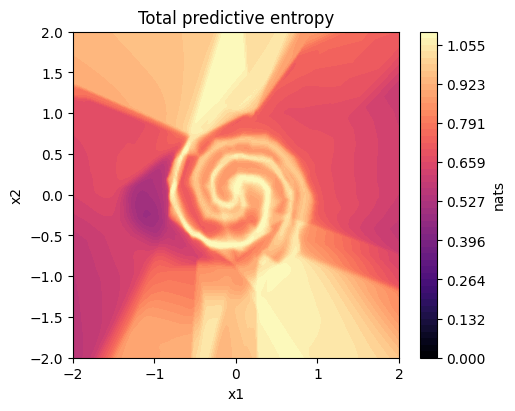

RESULTS_JSON={"mimo": [{"M": 1, "accuracy": 0.9473333358764648, "NLL": 0.1854575127363205, "parameters": 23553, "updates": 2000, "total_inside": 0.15142396791456172, "total_outside": 0.02459820774411625, "disagreement_inside": 0.0, "disagreement_outside": 0.0, "low_outside_xy": [-2.0, -2.0], "low_outside_entropy": -0.0, "high_total_xy": [0.0, 0.0], "high_total": 1.0907180770009053, "high_total_member_entropy": 1.0907180770009053, "high_total_disagreement": 0.0, "max_disagreement_xy": [-2.0, -2.0], "max_disagreement": 0.0}, {"M": 4, "accuracy": 0.9366666674613953, "NLL": 0.185370072722435, "parameters": 25812, "updates": 2000, "total_inside": 0.2979340172076862, "total_outside": 0.2591095694001534, "disagreement_inside": 0.10259180112314079, "disagreement_outside": 0.22996337613144746, "low_outside_xy": [-1.649999976158142, 2.0], "low_outside_entropy": 9.278538890096313e-23, "high_total_xy": [0.15000000596046448, -0.5], "high_total": 1.0939790426934732, "high_total_member_entropy": 0.61

In [23]:
import json
axis = np.linspace(-2, 2, 81, dtype=np.float32)
diagnostic_grid = jnp.asarray(np.array([(a, b) for a in axis for b in axis]))
outside_disk = np.linalg.norm(np.asarray(diagnostic_grid), axis=1) > 1

def uncertainty_metrics(probabilities):
    total, average = js_terms(np.asarray(probabilities))
    disagreement = np.maximum(total - average, 0)
    outside_indices = np.flatnonzero(outside_disk)
    low_index = outside_indices[np.argmin(total[outside_disk])]
    high_index = int(np.argmax(total))
    disagreement_index = int(np.argmax(disagreement))
    return dict(total_inside=float(total[~outside_disk].mean()),
                total_outside=float(total[outside_disk].mean()),
                disagreement_inside=float(disagreement[~outside_disk].mean()),
                disagreement_outside=float(disagreement[outside_disk].mean()),
                low_outside_xy=np.asarray(diagnostic_grid[low_index]).tolist(),
                low_outside_entropy=float(total[low_index]),
                high_total_xy=np.asarray(diagnostic_grid[high_index]).tolist(),
                high_total=float(total[high_index]),
                high_total_member_entropy=float(average[high_index]),
                high_total_disagreement=float(disagreement[high_index]),
                max_disagreement_xy=np.asarray(diagnostic_grid[disagreement_index]).tolist(),
                max_disagreement=float(disagreement[disagreement_index]))


mimo_comparison = []
for heads in (1, 4, 8):
    if heads == 4:
        model = params_mimo
    else:
        mi, mu, mg = optimizers.adam(0.1)
        model = init_network_params([D * heads, 150, 150, K * heads], random.PRNGKey(0))
        state = mi(model)
        stream = random.PRNGKey(1)
        for epoch in range(2000):
            stream, seed = random.split(stream)
            model, state = update_mimo(epoch, model, X, y_onehot, state,
                                      heads, 1e-3, seed, mu, mg)
    lp = mimo_log_probabilities(model, X_test, heads)
    _, probs = evalMIMO(model, diagnostic_grid, heads)
    row = dict(M=heads, accuracy=float(jnp.mean(jnp.argmax(lp, axis=-1) == y_test)),
               NLL=float(-jnp.mean(lp[jnp.arange(len(y_test)), y_test])),
               parameters=sum(a.size for a in jax.tree_util.tree_leaves(model)),
               updates=2000, **uncertainty_metrics(probs))
    assert np.isfinite([row["accuracy"], row["NLL"]]).all()
    mimo_comparison.append(row)
    print("Finished MIMO:", heads, "heads; held-out accuracy", row["accuracy"], "NLL", row["NLL"])
    if heads != 4:
        visualize_predictions(X, y, model, num_nets=heads)
print("RESULTS_JSON=" + json.dumps(dict(mimo=mimo_comparison)))


### Worked discussion — MIMO
These are results from the saved Kaggle run. Each configuration has two hidden layers of width 150, the same data and seed choices, and 2,000 full-batch updates. Evaluation repeats the same input in every slot and averages class probabilities.

| Heads | Parameters | Accuracy | NLL | Entropy inside | Entropy outside | Disagreement inside | Disagreement outside |
| --- | --- | --- | --- | --- | --- | --- | --- |
| 1 | 23553 | 0.9473 | 0.1855 | 0.1514 | 0.0246 | 0.0000 | 0.0000 |
| 4 | 25812 | 0.9367 | 0.1854 | 0.2979 | 0.2591 | 0.1026 | 0.2300 |
| 8 | 28824 | 0.9073 | 0.5294 | 0.8668 | 0.8095 | 0.2403 | 0.4348 |

1. Compared with the clean four-member deep ensemble, four-head MIMO has accuracy 0.9367 versus 0.9470, and NLL 0.1854 versus 0.1626. Average grid entropy outside the disk is 0.2591 versus 0.0808; outside disagreement is 0.2300 versus 0.0644. Both methods can be confident outside the observed support. For MIMO, one low-entropy outside point is [-1.649999976158142, 2.0], with entropy 0.0000.
2. One head necessarily has zero head disagreement. Adding heads does not guarantee monotonic accuracy, NLL, entropy or diversity: use the measured rows above. All heads share the hidden layers, so more heads must share the same hidden capacity while fitting independently paired training examples. The expanded input/output layers add parameters, but do not turn the heads into independent posterior samples.
3. For two 150-unit hidden layers, $D=2$ and $K=3$, the parameter count is $22,800+753M$: 23,553, 25,812 and 28,824 for 1, 4 and 8 heads. Four separate Part I networks require 94,212 parameters. Part I uses 300 updates per model (1,200 member updates total), whereas MIMO uses 2,000 shared-model updates. The tuple sizes and computation per update differ, so these results are a qualitative comparison, not a matched-compute or speed benchmark. Compilation and device synchronization would also need to be accounted for in a controlled timing experiment.
4. **Personal completion time:** My approximate study time for this course is of 4 hours

The numerical grid is coarser than the displayed maps, so reported extrema are extrema of that grid. Entropy/disagreement are model-based proxies, and held-out NLL is not a complete calibration assessment.

**Observed head-count trade-off:** Increasing heads from 1 to 4 to 8 reduces held-out accuracy from 94.7333% to 93.6667% to 90.7333%. NLL is nearly unchanged between 1 and 4 heads (0.18546 versus 0.18537), then worsens to 0.52940 with 8 heads. Average total entropy and disagreement increase in both regions, but this increased uncertainty is not evidence of better predictive performance or calibration. Four-head MIMO shows substantially more average disagreement outside the disk (0.2300) than the clean deep ensemble (0.0644), while the deep ensemble has better held-out accuracy and NLL.


## Reflection on LLM use and learning

### 1. Which LLM I used and how
I used OpenAI Codex, a GPT-6-based assistant, as a tutor, coding assistant and writing aid during this practical. My use went beyond formatting: it included explanations, implementation suggestions, generated code, debugging, and help drafting interpretations and this reflection.

For the mathematics, I asked the assistant to convert equations into LaTeX that I could paste into notebook Markdown cells. I also asked it to explain the intermediate steps in the Gaussian KL derivation: expanding the two log densities and taking expectations under $Q_\omega(\theta)$. In particular, the identities $\mathbb E_Q[(\theta_j-\mu_j)^2]=\sigma_j^2$ and $\mathbb E_Q[\theta_j^2]=\mu_j^2+\sigma_j^2$ explain where the terms in the closed-form KL come from. Here $Q_\omega$ is the **approximate posterior**, while $P(\theta)$ is the prior. This distinction helped me connect the mathematical objective to the implementation.

The assistant explained variable types, array shapes, and the supplied helper functions, allowing me to focus on how they fit into the TODO components. It helped implement the VI loss and reparameterized layer, completed ensemble/MIMO implementations and comparison code, and generated a self-contained JAX MNIST deep-ensemble extension because the referenced starter script was not available in my workspace. It also helped compare the saved results with the written discussions and corrected a variance-versus-standard-deviation error in my first written Gaussian derivation. I ran the notebooks on Kaggle and supplied the resulting files for review. Some earlier ensemble checks were run by the assistant locally; the final numerical discussions use the saved Kaggle results. The assistant helped draft this disclosure and prepare the PDF exports.

### 2. Benefits and limitations for my learning
The main benefit was reducing the time spent on unfamiliar JAX syntax, helper-function interfaces and equation formatting. Step-by-step explanations helped connect the probability distributions to executable operations: summing over observations, summing over parameter coordinates, applying softplus to standard deviations, and sampling with the reparameterization trick. This made it easier to concentrate on the purpose of each loss term and on the differences between aleatoric and epistemic uncertainty.

The main drawback is that receiving complete code can replace the practice of constructing and debugging an implementation myself. A notebook that runs is not evidence that I could reproduce every part unaided. Fluent explanations can also appear more reliable than they are. During this work, the written Gaussian derivation needed correction, and discussion values from an earlier run had to be replaced with the actual Kaggle outputs. These are reasons to check both the mathematics and the evidence rather than accept generated text automatically.

My assessment is that LLM support improved my access to the concepts and my ability to finish the experiments, but reduced the amount of independent implementation practice. To consolidate the learning, I should be able to derive the losses, explain the tensor shapes and trace the sampling and ensembling code without referring to the assistant. I regard generated code as something I must understand and defend, not as evidence of mastery on its own.

### 3. Should LLM use be allowed?
I support allowing LLMs in practical assignments with transparent disclosure and responsibility for the submitted work. They can help students overcome programming and notation barriers while exploring the intended concepts. However, unrestricted copying without understanding would weaken the learning objective and make assessment less informative.

A useful policy would distinguish tutoring, formatting, debugging and code generation, and require students to state which forms of help they used. Students should verify generated claims against their actual experiments and be prepared to explain a derivation or modify part of the implementation independently. Short oral questions or an unaided component could assess that understanding. This would preserve the educational benefits of LLM assistance while assessing what the student has learned, rather than only the quality of the final generated notebook.
